# Decision tree for default classification

Same setup as notebook 02: **only the 80% training set**, the **same 5 stratified folds**, the same preprocessing inside the pipeline, and **F1** as the main metric. The test set stays locked.

**No SMOTE here.** Notebook 02 showed for logistic regression and the SVMs that SMOTE never improved F1 once the cutoff was tuned (it only traded precision for recall). Trees and forests are therefore trained on the real data; class imbalance is handled by **tuning the cutoff**.

**How a classification tree works.** Starting from all applicants, the tree repeatedly asks the single yes/no question (e.g. *loan_percent_income ≤ 0.30?*) that makes the two resulting groups as **pure** as possible (mostly defaulters or mostly non-defaulters). Purity is measured by

$$\text{Gini} = 1 - \sum_k p_k^2 \qquad \text{or} \qquad \text{Entropy} = -\sum_k p_k \log_2 p_k$$

where $p_k$ is the share of class $k$ in the node. Each **leaf** predicts the share of defaulters among the training applicants that reached it, which is the tree's probability of default (`predict_proba`).

## Hyperparameters

| Hyperparameter | What it controls | Too small | Too large |
|---|---|---|---|
| `max_depth` | maximum number of questions from root to leaf | **underfits** | **overfits** (memorises single applicants) |
| `min_samples_leaf` | minimum applicants allowed in a leaf | noisy leaves, overfits | coarse rules, underfits |
| `criterion` | impurity measure: `gini` or `entropy` | (usually a small effect) | |
| `min_samples_split`, `max_leaf_nodes` | other ways to limit the size of the tree | | |
| `ccp_alpha` | cost-complexity pruning: grow the full tree, then cut back branches worth less than α per leaf | | |

We tune the three most important (**max_depth, min_samples_leaf, criterion**) with 5-fold CV. Pruning with `ccp_alpha` is an alternative way to control tree size; it is not needed here.

Trees do not need scaling; the shared preprocessing still scales the numeric columns, which does not change any split.

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import f1_score

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.credit import (RANDOM_STATE, REPORTS, load_train, make_cv, make_preprocess, make_pipeline,
                        f1_curve, best_cutoff, fold_metrics)

X_train, y_train = load_train()
cv = make_cv()
print("X_train:", X_train.shape, f"  default rate: {y_train.mean():.4f}")
print("folds:", [len(v) for _, v in cv.split(X_train, y_train)])

X_train: (25927, 11)   default rate: 0.2187
folds: [5186, 5186, 5185, 5185, 5185]


## Step 1: A fully grown tree (no limits)

With no hyperparameters set, the tree splits until every leaf is pure. We compare **train F1** (on the 4 folds it learned from) with **validation F1** (the 5th fold) in each round.

In [2]:
r = cross_validate(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), X_train, y_train, cv=cv,
                   scoring=["precision", "recall", "f1", "roc_auc"], return_train_score=True,
                   return_estimator=True, n_jobs=5)
rows = []
for k, est in enumerate(r["estimator"]):
    t = est.named_steps["model"]
    rows.append({"round": k + 1, "train F1": r["train_f1"][k], "val F1": r["test_f1"][k],
                 "val precision": r["test_precision"][k], "val recall": r["test_recall"][k],
                 "val ROC-AUC": r["test_roc_auc"][k], "depth": t.get_depth(), "leaves": t.get_n_leaves()})
full = pd.DataFrame(rows).set_index("round").astype(float)
full.loc["mean"] = full.mean()
display(full.round(4))

,train F1,val F1,val precision,val recall,val ROC-AUC,depth,leaves
round,,,,,,,
1,1.0,0.7513,0.7410,0.7619,0.8437,32.0,1824.0
2,1.0,0.7477,0.7341,0.7619,0.8423,35.0,1837.0
3,1.0,0.7451,0.7189,0.7734,0.8443,32.0,1852.0
4,1.0,0.7445,0.7438,0.7451,0.8367,36.0,1842.0
5,1.0,0.7398,0.7302,0.7496,0.8360,33.0,1839.0
mean,1.0,0.7457,0.7336,0.7584,0.8406,33.6,1838.8


## Step 2: How depth controls over- and underfitting

Train and validation F1 for `max_depth` = 1 … 20 (everything else default). The gap between the two curves is overfitting. (Step 1 is the far end of this curve: the fully grown tree reaches depth ~34.)

best max_depth by mean validation F1: 12  (val F1 = 0.8083)


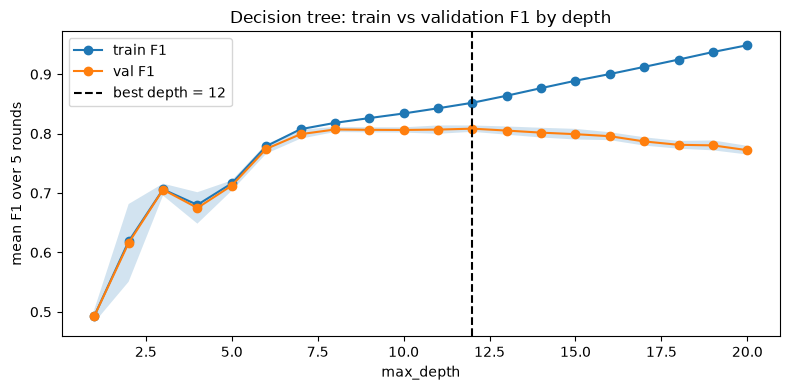

In [3]:
depth_rows = []
for d in range(1, 21):
    r = cross_validate(make_pipeline(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)),
                       X_train, y_train, cv=cv, scoring="f1", return_train_score=True, n_jobs=5)
    depth_rows.append({"max_depth": d, "train F1": r["train_score"].mean(),
                       "val F1": r["test_score"].mean(), "val F1 sd": r["test_score"].std()})
depth_curve = pd.DataFrame(depth_rows).set_index("max_depth")
best_d = depth_curve["val F1"].idxmax()
print(f"best max_depth by mean validation F1: {best_d}  (val F1 = {depth_curve.loc[best_d, 'val F1']:.4f})")

ax = depth_curve[["train F1", "val F1"]].plot(marker="o", figsize=(8, 4))
ax.fill_between(depth_curve.index, depth_curve["val F1"] - depth_curve["val F1 sd"],
                depth_curve["val F1"] + depth_curve["val F1 sd"], alpha=0.2)
ax.axvline(best_d, color="black", linestyle="--", label=f"best depth = {best_d}")
ax.set_xlabel("max_depth"); ax.set_ylabel("mean F1 over 5 rounds")
ax.set_title("Decision tree: train vs validation F1 by depth")
ax.legend(); plt.tight_layout(); plt.show()

## Step 3: Tuning max_depth × min_samples_leaf × criterion

A small grid around the good region from Step 2. Every combination is scored with 5-fold CV; best = highest **mean validation F1** at the default cutoff (probability ≥ 0.5).

In [4]:
tree_grid = {"model__max_depth": [6, 8, 10, 12, 15],
             "model__min_samples_leaf": [1, 5, 20],
             "model__criterion": ["gini", "entropy"]}
gs = GridSearchCV(make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)), tree_grid,
                  cv=cv, scoring="f1", n_jobs=-1)
start = time.time()
gs.fit(X_train, y_train)
tree_res = (pd.DataFrame(gs.cv_results_)
              .rename(columns={"param_model__max_depth": "max_depth",
                               "param_model__min_samples_leaf": "min_samples_leaf",
                               "param_model__criterion": "criterion",
                               "mean_test_score": "mean F1", "std_test_score": "sd F1"})
              [["max_depth", "min_samples_leaf", "criterion", "mean F1", "sd F1", "rank_test_score"]]
              .sort_values("rank_test_score"))
print(f"{len(tree_res)} combinations x 5 folds in {time.time() - start:.0f}s. Top 5 by mean validation F1:")
display(tree_res.head(5).round(4))

b = tree_res.iloc[0]
tree_params = {"max_depth": int(b["max_depth"]), "min_samples_leaf": int(b["min_samples_leaf"]),
               "criterion": b["criterion"]}
print("chosen:", tree_params)

30 combinations x 5 folds in 16s. Top 5 by mean validation F1:


,max_depth,min_samples_leaf,criterion,mean F1,sd F1,rank_test_score
21,10,1,entropy,0.8113,0.0039,1
24,12,1,entropy,0.8097,0.0048,2
22,10,5,entropy,0.8096,0.0045,3
9,12,1,gini,0.8083,0.0054,4
25,12,5,entropy,0.8078,0.0054,5


chosen: {'max_depth': 10, 'min_samples_leaf': 1, 'criterion': 'entropy'}


## Step 4: Cutoff tuning (exact search)

The tree is a candidate for the final model, so it gets the same cutoff tuning as the other models: **out-of-fold probabilities** with `cross_val_predict(..., method="predict_proba")`, then every distinct probability is tried as the cutoff and the highest F1 is kept, with a per-fold check. A tree only produces as many distinct probabilities as it has leaves, so the F1 curve is a staircase.

best cutoff 0.600  (each fold's own best: [0.5, 0.641, 0.6, 0.704, 0.628])
F1 at 0.5 = 0.8115  ->  F1 at 0.600 = 0.8128;  tuned cutoff beats 0.5 in 3 of 5 rounds


,accuracy,precision,recall,f1,roc_auc
round,,,,,
1,0.9315,0.9803,0.7011,0.8175,0.9129
2,0.9294,0.9752,0.6949,0.8115,0.9072
3,0.9286,0.9659,0.6984,0.8106,0.9019
4,0.9279,0.9589,0.7002,0.8094,0.9003
5,0.9304,0.9731,0.7011,0.8150,0.9088
mean,0.9296,0.9707,0.6991,0.8128,0.9062
sd,0.0014,0.0084,0.0026,0.0033,0.0051


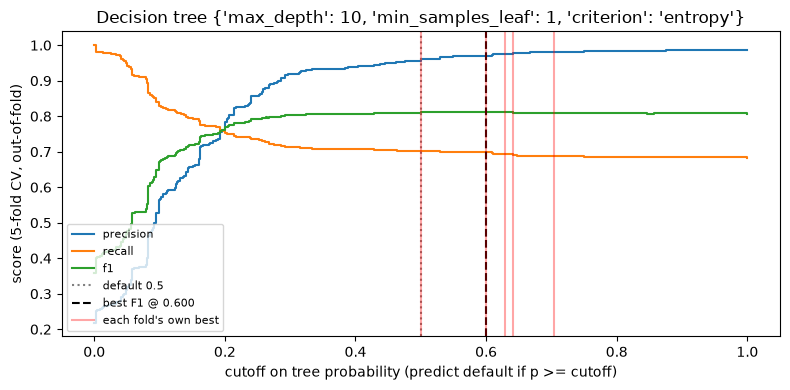

In [5]:
pipe = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE, **tree_params))
p = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba", n_jobs=5)[:, 1]
cut = best_cutoff(p, y_train)
at05, atb = fold_metrics(p, y_train, 0.5, X_train, cv), fold_metrics(p, y_train, cut, X_train, cv)
own = [best_cutoff(p[v], y_train.iloc[v]) for _, v in cv.split(X_train, y_train)]
beats = sum(f1_score(y_train.iloc[v], (p[v] >= cut).astype(int)) > f1_score(y_train.iloc[v], (p[v] >= 0.5).astype(int))
            for _, v in cv.split(X_train, y_train))
print(f"best cutoff {cut:.3f}  (each fold's own best: {np.round(own, 3).tolist()})")
print(f"F1 at 0.5 = {at05.loc['mean', 'f1']:.4f}  ->  F1 at {cut:.3f} = {atb.loc['mean', 'f1']:.4f};  "
      f"tuned cutoff beats 0.5 in {beats} of 5 rounds")
display(atb.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
f1_curve(p, y_train).plot(ax=ax, drawstyle="steps-post")
ax.axvline(0.5, color="grey", linestyle=":", label="default 0.5")
ax.axvline(cut, color="black", linestyle="--", label=f"best F1 @ {cut:.3f}")
for i, c in enumerate(own):
    ax.axvline(c, color="red", alpha=0.35, label="each fold's own best" if i == 0 else None)
ax.set_xlabel("cutoff on tree probability (predict default if p >= cutoff)")
ax.set_ylabel("score (5-fold CV, out-of-fold)"); ax.set_title(f"Decision tree {tree_params}")
ax.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

## Step 5: What the tree learned

**A readable tree.** A depth-3 tree (same `criterion` as the chosen tree) fitted on the whole training set, only to *show* the top rules; it is not used for evaluation. Numeric thresholds are on the standardised scale, e.g. `loan_percent_income ≤ 1.26` ≈ loan ≤ 31% of income. A one-hot column such as `person_home_ownership_RENT ≤ 0.5` means *not* a renter.

**Feature importance of the chosen tree.** Impurity-based importance (how much each feature reduced impurity across all its splits). It is biased toward features with many possible split points, so treat it as indicative.

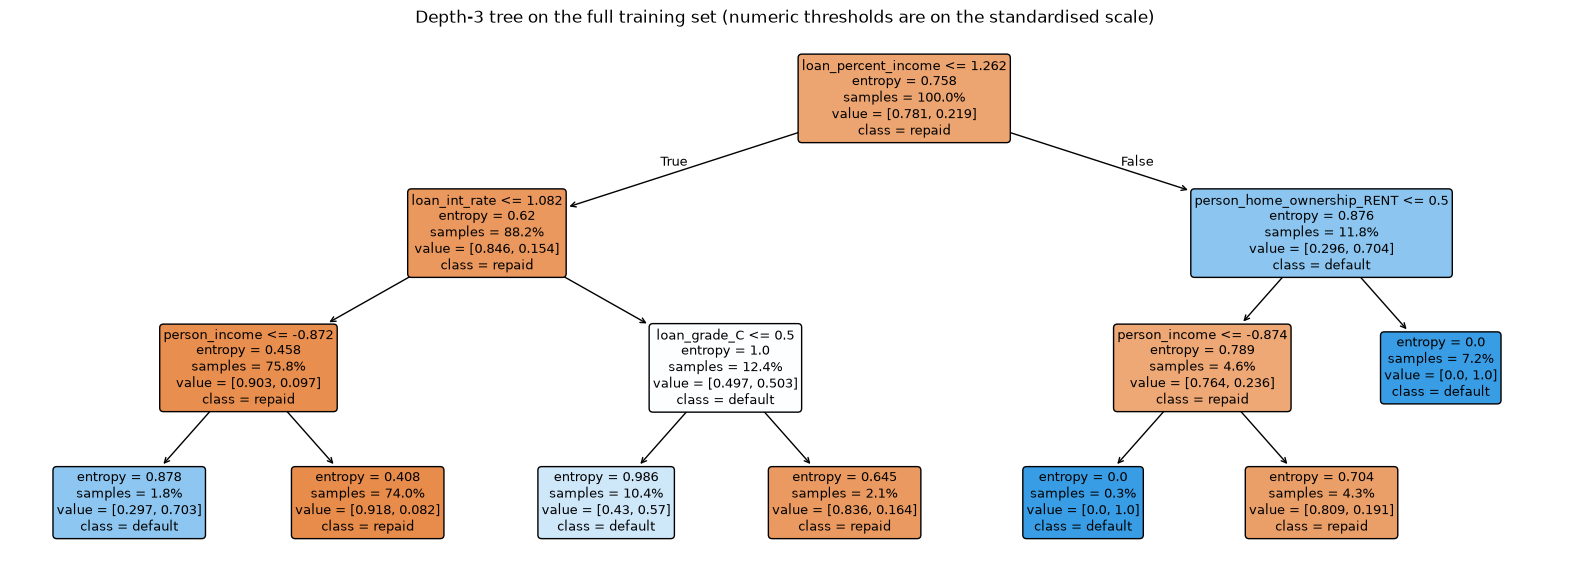

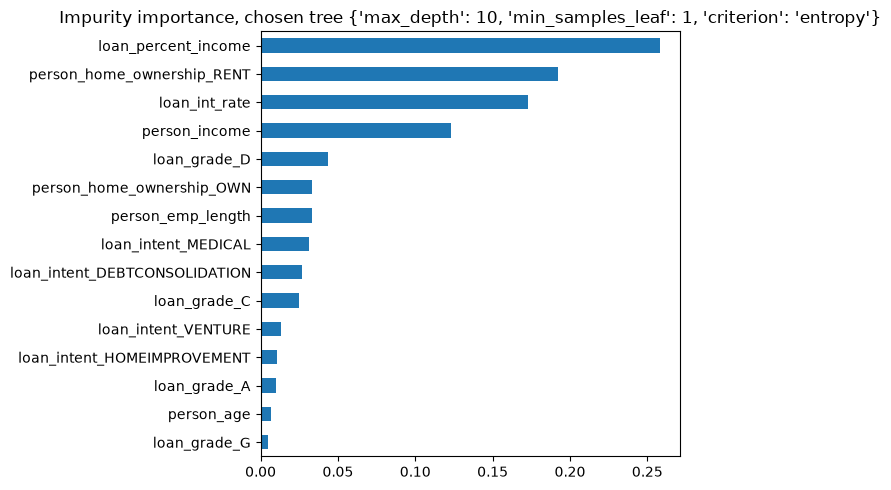

In [6]:
small = make_pipeline(DecisionTreeClassifier(max_depth=3, criterion=tree_params["criterion"],
                                             random_state=RANDOM_STATE)).fit(X_train, y_train)
names = [n.replace("num__", "").replace("cat__", "") for n in small.named_steps["prep"].get_feature_names_out()]
fig, ax = plt.subplots(figsize=(20, 7))
plot_tree(small.named_steps["model"], feature_names=names, class_names=["repaid", "default"],
          filled=True, rounded=True, impurity=True, proportion=True, fontsize=9, ax=ax)
ax.set_title("Depth-3 tree on the full training set (numeric thresholds are on the standardised scale)")
plt.show()

chosen = make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE, **tree_params)).fit(X_train, y_train)
imp = pd.Series(chosen.named_steps["model"].feature_importances_, index=names).sort_values()
imp[imp > 0.005].plot.barh(figsize=(7, 5), title=f"Impurity importance, chosen tree {tree_params}")
plt.tight_layout(); plt.show()

## Step 6: Leaderboard and saved choice

The tree next to the cutoff-tuned results from notebook 02 (copied from its Step 6d leaderboard; same folds, same exact cutoff search). The chosen settings and cutoff are saved to `reports/decision_tree_choice.json` for the later notebooks.

In [7]:
from_nb02 = pd.DataFrame([
    {"model": "SVM RBF (no SMOTE), C=100, gamma=0.03", "F1 @ default": 0.7824, "best cutoff": -0.143,
     "precision @ best": 0.9084, "recall @ best": 0.6905, "F1 @ best": 0.7845, "roc_auc": 0.9058},
    {"model": "SVM RBF + SMOTE, C=30, gamma=0.03", "F1 @ default": 0.7573, "best cutoff": 0.397,
     "precision @ best": 0.8683, "recall @ best": 0.6963, "F1 @ best": 0.7728, "roc_auc": 0.9080},
    {"model": "LogReg (no SMOTE)", "F1 @ default": 0.6463, "best cutoff": 0.330,
     "precision @ best": 0.6543, "recall @ best": 0.6996, "F1 @ best": 0.6762, "roc_auc": 0.8688},
    {"model": "LogReg + SMOTE", "F1 @ default": 0.6435, "best cutoff": 0.670,
     "precision @ best": 0.6796, "recall @ best": 0.6681, "F1 @ best": 0.6738, "roc_auc": 0.8697},
]).set_index("model")
label = "Tree, " + ", ".join(f"{k}={v}" for k, v in tree_params.items())
tree_row = pd.DataFrame([{"model": label, "F1 @ default": at05.loc["mean", "f1"], "best cutoff": round(cut, 3),
                          "precision @ best": atb.loc["mean", "precision"], "recall @ best": atb.loc["mean", "recall"],
                          "F1 @ best": atb.loc["mean", "f1"], "roc_auc": at05.loc["mean", "roc_auc"]}]).set_index("model")
board = pd.concat([from_nb02, tree_row]).sort_values("F1 @ best", ascending=False)
print("Leaderboard (5-fold CV on the training set, each model at its own tuned cutoff):")
display(board.round(4))

REPORTS.mkdir(exist_ok=True)
choice = {"Tree": {"params": tree_params, "cutoff": cut, "cv_f1_at_cutoff": float(atb.loc["mean", "f1"]),
                   "cv_f1_at_default": float(at05.loc["mean", "f1"]),
                   "cv_precision_at_cutoff": float(atb.loc["mean", "precision"]),
                   "cv_recall_at_cutoff": float(atb.loc["mean", "recall"]),
                   "cv_roc_auc": float(at05.loc["mean", "roc_auc"])}}
(REPORTS / "decision_tree_choice.json").write_text(json.dumps(choice, indent=2))
print("saved reports/decision_tree_choice.json:\n", json.dumps(choice, indent=2))

Leaderboard (5-fold CV on the training set, each model at its own tuned cutoff):


,F1 @ default,best cutoff,precision @ best,recall @ best,F1 @ best,roc_auc
model,,,,,,
"Tree, max_depth=10, min_samples_leaf=1, criterion=entropy",0.8115,0.600,0.9707,0.6991,0.8128,0.9062
"SVM RBF (no SMOTE), C=100, gamma=0.03",0.7824,-0.143,0.9084,0.6905,0.7845,0.9058
"SVM RBF + SMOTE, C=30, gamma=0.03",0.7573,0.397,0.8683,0.6963,0.7728,0.9080
LogReg (no SMOTE),0.6463,0.330,0.6543,0.6996,0.6762,0.8688
LogReg + SMOTE,0.6435,0.670,0.6796,0.6681,0.6738,0.8697


saved reports/decision_tree_choice.json:
 {
  "Tree": {
    "params": {
      "max_depth": 10,
      "min_samples_leaf": 1,
      "criterion": "entropy"
    },
    "cutoff": 0.6,
    "cv_f1_at_cutoff": 0.8128009841403669,
    "cv_f1_at_default": 0.8115407845574705,
    "cv_precision_at_cutoff": 0.9706763733631923,
    "cv_recall_at_cutoff": 0.6991181657848324,
    "cv_roc_auc": 0.9062249524145507
  }
}
